# UPI Shield: Explainable, Cost-Aware Fraud Detection on Synthetic UPI Transactions

**Goal:** flag risky UPI payments *before the money moves*, explain every flag in plain English, and choose the alert threshold by **rupees saved**, not by accuracy.

| Typical fraud notebook | This project |
|---|---|
| Random Kaggle CSV, no story | Synthetic data built from **4 real UPI scam patterns** (collect-request, QR, account takeover, mule accounts) |
| Raw columns only | **Behaviour features**: "is this normal for *this* user?" |
| Random train/test split | **Time-based split** (train on past, test on future), like a real deployment |
| Accuracy / F1 | **PR-AUC + rupee cost**: missed fraud = amount lost, false alarm = customer friction |
| Yes/No output | **Allow / OTP step-up / Block** tiers + **reason codes** for every flagged payment |

### Contents
1. Why synthetic data
2. Generate the data
3. Data check
4. Exploratory analysis (EDA)
5. Feature engineering
6. Time-based split
7. Models
8. Evaluation
9. Cost-based threshold and risk tiers
10. Explainability (SHAP + reason codes)
11. Conclusion, limitations, next steps

## 1. Why synthetic data (and not a Kaggle CSV)?

- **Real UPI transaction data is private.** Banks and NPCI do not publish it.
- Public "UPI fraud" CSVs on Kaggle are mostly random rows with no user history and no reliable timestamps. Without history you cannot ask the most useful fraud question: *"Is this unusual for this user?"*
- With my own generator I **control the fraud patterns**, so I can later check *which scam types* the model catches and which it misses.

**Honest limitation:** a model is only as realistic as its data. I base the patterns on publicly reported UPI scams, but real fraud is messier and keeps changing.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay, accuracy_score)
from xgboost import XGBClassifier
import shap

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
SEED = 42

## 2. Generate the synthetic UPI data

**Normal behaviour.** About 2,000 users over 6 months (~50k payments).
- Each user has a usual spend level, a set of regular payees (friends, shops), and a usual phone.
- Most payments happen in the daytime. About 10% of users are "night owls", so legit night payments exist too.
- Some realistic noise: legit phone changes, occasional big purchases, and young (but genuine) payee accounts.

**Four fraud patterns** (about 2% of payments):

| Fraud type | What happens in real life | Signals it leaves |
|---|---|---|
| `collect_request_scam` | Scammer sends a *money request*; victim approves it thinking they will *receive* money | COLLECT request, new payee, often a round amount |
| `qr_scam` | Victim scans a QR "to receive a refund" and pays instead | QR payment to a new, non-merchant payee |
| `account_takeover` | SIM swap or stolen phone; attacker drains the account | New device, night time, very high amount, burst of payments |
| `mule_payee` | One mule account collects money from many victims | Payee suddenly gets money from many *new* senders |

To keep the problem honest, about 30% of scam accounts are **old accounts** (bought or rented), so "young payee account" is not a perfect giveaway.

In [2]:
def generate_upi_data(n_users=2000, days=180, seed=SEED):
    rng = np.random.default_rng(seed)
    start = pd.Timestamp("2025-01-01")

    # ---- hour-of-day patterns ----
    day_p = np.array([1, .5, .3, .2, .2, .4, 1, 2, 4, 6, 7, 7, 8, 7, 6, 6, 7, 8, 9, 9, 8, 6, 4, 2], float)
    night_owl_p = day_p.copy()
    night_owl_p[[22, 23, 0, 1, 2]] += [4, 5, 5, 4, 2]
    day_p, night_owl_p = day_p / day_p.sum(), night_owl_p / night_owl_p.sum()

    # ---- payees: merchants, individuals, scam accounts, mule accounts ----
    # payee_info[id] = (is_merchant, day the account was created relative to the start date)
    payee_info = {}
    merchants = [f"M{i:04d}" for i in range(400)]
    persons = [f"P{i:04d}" for i in range(3000)]
    for m in merchants:
        payee_info[m] = (1, -int(rng.integers(200, 3000)))
    for p in persons:                                          # 15% of genuine accounts open during the period
        created = rng.uniform(-30, days) if rng.random() < 0.15 else -rng.integers(30, 3000)
        payee_info[p] = (0, float(created))

    def account_created(active_from):
        # 70% fresh accounts; 30% old accounts bought or rented by scammers
        back = rng.integers(1, 60) if rng.random() < 0.7 else rng.integers(200, 1500)
        return float(active_from - back)

    # scam accounts get reported and replaced, so each one is only used for ~25 days
    scam_active = {}
    for i in range(250):
        s, a = f"S{i:03d}", rng.uniform(-10, days)
        scam_active[s] = a
        payee_info[s] = (0, account_created(a))

    def scam_account(day):
        live = [s for s, a in scam_active.items() if a <= day < a + 25]
        return rng.choice(live) if live else rng.choice(list(scam_active))

    mules = [f"X{i:03d}" for i in range(15)]

    # ---- users ----
    users = []
    for i in range(n_users):
        users.append(dict(
            uid=f"U{i:04d}",
            avg=float(rng.lognormal(np.log(600), 0.8)),               # usual spend level (Rs)
            n=max(3, int(rng.poisson(rng.gamma(2, 12.5)))),           # activity level
            hour_p=night_owl_p if rng.random() < 0.10 else day_p,
            fav_persons=list(rng.choice(persons, rng.integers(3, 9), replace=False)),
            fav_merchants=list(rng.choice(merchants, rng.integers(3, 9), replace=False)),
            phone_change_day=rng.uniform(30, 170) if rng.random() < 0.15 else None,
        ))

    def device_at(u, day):
        if u["phone_change_day"] is not None and day >= u["phone_change_day"]:
            return f"{u['uid']}_D1"
        return f"{u['uid']}_D0"

    def ts_of(day, hour, minute):
        return start + pd.Timedelta(days=int(day), hours=int(hour), minutes=float(minute))

    rows = []

    # ---- normal payments ----
    for u in users:
        for _ in range(u["n"]):
            day = rng.uniform(0, days)
            p2m = rng.random() < 0.55
            if p2m:
                payee = rng.choice(u["fav_merchants"]) if rng.random() < 0.80 else rng.choice(merchants)
            else:
                payee = rng.choice(u["fav_persons"]) if rng.random() < 0.85 else rng.choice(persons)
            amount = u["avg"] * rng.lognormal(0, 0.6)
            if rng.random() < 0.01:                                   # occasional big legit purchase
                amount *= rng.uniform(5, 15)
            device = device_at(u, day)
            if rng.random() < 0.005:                                  # borrowed / family phone
                device = f"{u['uid']}_DX{rng.integers(1000)}"
            rows.append(dict(
                timestamp=ts_of(day, rng.choice(24, p=u["hour_p"]), rng.uniform(0, 60)),
                sender_id=u["uid"], payee_id=payee, amount=amount,
                request_type="COLLECT" if rng.random() < (0.08 if p2m else 0.05) else "PAY",
                via_qr=int(rng.random() < (0.60 if p2m else 0.25)),   # small shops often use personal QR
                device_id=device, fraud_type="none"))

    def victim():
        return users[rng.integers(n_users)]

    def scam_amount(u):
        if rng.random() < 0.4:
            return float(rng.choice([499, 999, 1999, 2999, 4999, 9999]))
        return u["avg"] * rng.uniform(0.5, 3)                         # many scams ask for "normal" amounts

    # ---- fraud 1: collect-request scam ----
    for _ in range(300):
        u, day = victim(), rng.uniform(0, days)
        rows.append(dict(timestamp=ts_of(day, rng.choice(24, p=day_p), rng.uniform(0, 60)),
                         sender_id=u["uid"], payee_id=scam_account(day), amount=scam_amount(u),
                         request_type="COLLECT", via_qr=0, device_id=device_at(u, day),
                         fraud_type="collect_request_scam"))

    # ---- fraud 2: QR scam ----
    for _ in range(200):
        u, day = victim(), rng.uniform(0, days)
        rows.append(dict(timestamp=ts_of(day, rng.choice(24, p=day_p), rng.uniform(0, 60)),
                         sender_id=u["uid"], payee_id=scam_account(day), amount=scam_amount(u),
                         request_type="PAY", via_qr=1, device_id=device_at(u, day),
                         fraud_type="qr_scam"))

    # ---- fraud 3: account takeover (burst of 2-4 payments) ----
    # 70%: SIM swap -> new device, often at night. 30%: remote-access app on the victim's own phone.
    for k in range(120):
        u, day = victim(), rng.uniform(0, days)
        sim_swap = rng.random() < 0.7
        hour = rng.integers(0, 6) if (sim_swap and rng.random() < 0.6) else rng.choice(24, p=day_p)
        t = ts_of(day, hour, rng.uniform(0, 60))
        device = f"{u['uid']}_ATO{k}" if sim_swap else device_at(u, day)
        payee = scam_account(day)
        for _ in range(rng.integers(2, 5)):
            rows.append(dict(timestamp=t, sender_id=u["uid"], payee_id=payee,
                             amount=min(u["avg"] * rng.uniform(2, 12), 100000.0),
                             request_type="PAY", via_qr=0, device_id=device,
                             fraud_type="account_takeover"))
            t += pd.Timedelta(minutes=float(rng.uniform(2, 20)))

    # ---- fraud 4: mule accounts collecting from many victims in ~36 hours ----
    for mule in mules:
        a = rng.uniform(0, days - 2)
        payee_info[mule] = (0, account_created(a))
        t0 = start + pd.Timedelta(days=float(a))
        for _ in range(rng.integers(10, 21)):
            u = victim()
            t = t0 + pd.Timedelta(hours=float(rng.uniform(0, 36)))
            day = (t - start).days
            rows.append(dict(timestamp=t, sender_id=u["uid"], payee_id=mule,
                             amount=u["avg"] * rng.uniform(0.8, 3),
                             request_type="PAY", via_qr=int(rng.random() < 0.3),
                             device_id=device_at(u, day), fraud_type="mule_payee"))

    df = pd.DataFrame(rows)
    df = df[df["timestamp"] < start + pd.Timedelta(days=days)]
    df["amount"] = df["amount"].clip(1, 100000).round(2)
    df["payee_is_merchant"] = df["payee_id"].map(lambda p: payee_info[p][0])
    # account age is measured on the payment date (an account gets older over time)
    pay_day = (df["timestamp"] - start).dt.days
    created = df["payee_id"].map(lambda p: payee_info[p][1])
    df["payee_account_age_days"] = (pay_day - created).clip(lower=1).astype(int)
    df["is_fraud"] = (df["fraud_type"] != "none").astype(int)
    df = df.sort_values("timestamp").reset_index(drop=True)
    df.insert(0, "txn_id", [f"T{i:06d}" for i in range(len(df))])
    return df


df = generate_upi_data()
import os
os.makedirs("data", exist_ok=True)
df.to_csv("data/upi_transactions.csv", index=False)
print(f"Generated {len(df):,} transactions -> data/upi_transactions.csv")
df.head()

Generated 52,896 transactions -> data/upi_transactions.csv


,txn_id,timestamp,sender_id,payee_id,amount,request_type,via_qr,device_id,fraud_type,payee_is_merchant,payee_account_age_days,is_fraud
0,T000000,2025-01-01 00:04:12.193901192,U0195,S040,"9,999.000",COLLECT,0,U0195_D0,collect_request_scam,0,296,1
1,T000001,2025-01-01 01:38:19.701534225,U1116,P2059,67.170,PAY,0,U1116_D0,none,0,1690,0
2,T000002,2025-01-01 01:46:24.634826535,U1395,M0330,444.540,PAY,1,U1395_D0,none,1,1731,0
3,T000003,2025-01-01 01:50:10.011527421,U0451,M0216,"2,110.350",PAY,1,U0451_D0,none,1,421,0
4,T000004,2025-01-01 02:10:45.035280699,U1293,M0287,"3,757.340",PAY,1,U1293_D0,none,1,1800,0


## 3. Data check
Shape, data types, missing values and class balance.

In [3]:
print("Shape:", df.shape)
print("Date range:", df["timestamp"].min().date(), "to", df["timestamp"].max().date())
print("Users:", df["sender_id"].nunique(), "| Payees:", df["payee_id"].nunique())
print("Missing values:", int(df.isna().sum().sum()))
print(f"\nFraud rate: {df['is_fraud'].mean():.2%}  ({df['is_fraud'].sum():,} fraud rows)")
df.dtypes

Shape: (52896, 12)
Date range: 2025-01-01 to 2025-06-29
Users: 2000 | Payees: 3565
Missing values: 0

Fraud rate: 2.01%  (1,065 fraud rows)


txn_id                               str
timestamp                 datetime64[ns]
sender_id                            str
payee_id                             str
amount                           float64
request_type                         str
via_qr                             int64
device_id                            str
fraud_type                           str
payee_is_merchant                  int64
payee_account_age_days             int64
is_fraud                           int64
dtype: object

**Why accuracy is the wrong metric.** A "model" that marks *every* payment as legit already looks great on accuracy:

In [4]:
dumb_pred = np.zeros(len(df))
print(f"Accuracy of 'never fraud' model: {accuracy_score(df['is_fraud'], dumb_pred):.2%}")
print(f"Fraud caught by it: 0 of {df['is_fraud'].sum():,}")

Accuracy of 'never fraud' model: 97.99%
Fraud caught by it: 0 of 1,065


So I use **PR-AUC** (how well the model ranks fraud above legit when fraud is rare), **recall** (share of fraud caught), **precision** (share of alerts that are real fraud) and finally **rupees saved**.

## 4. Exploratory analysis (EDA)

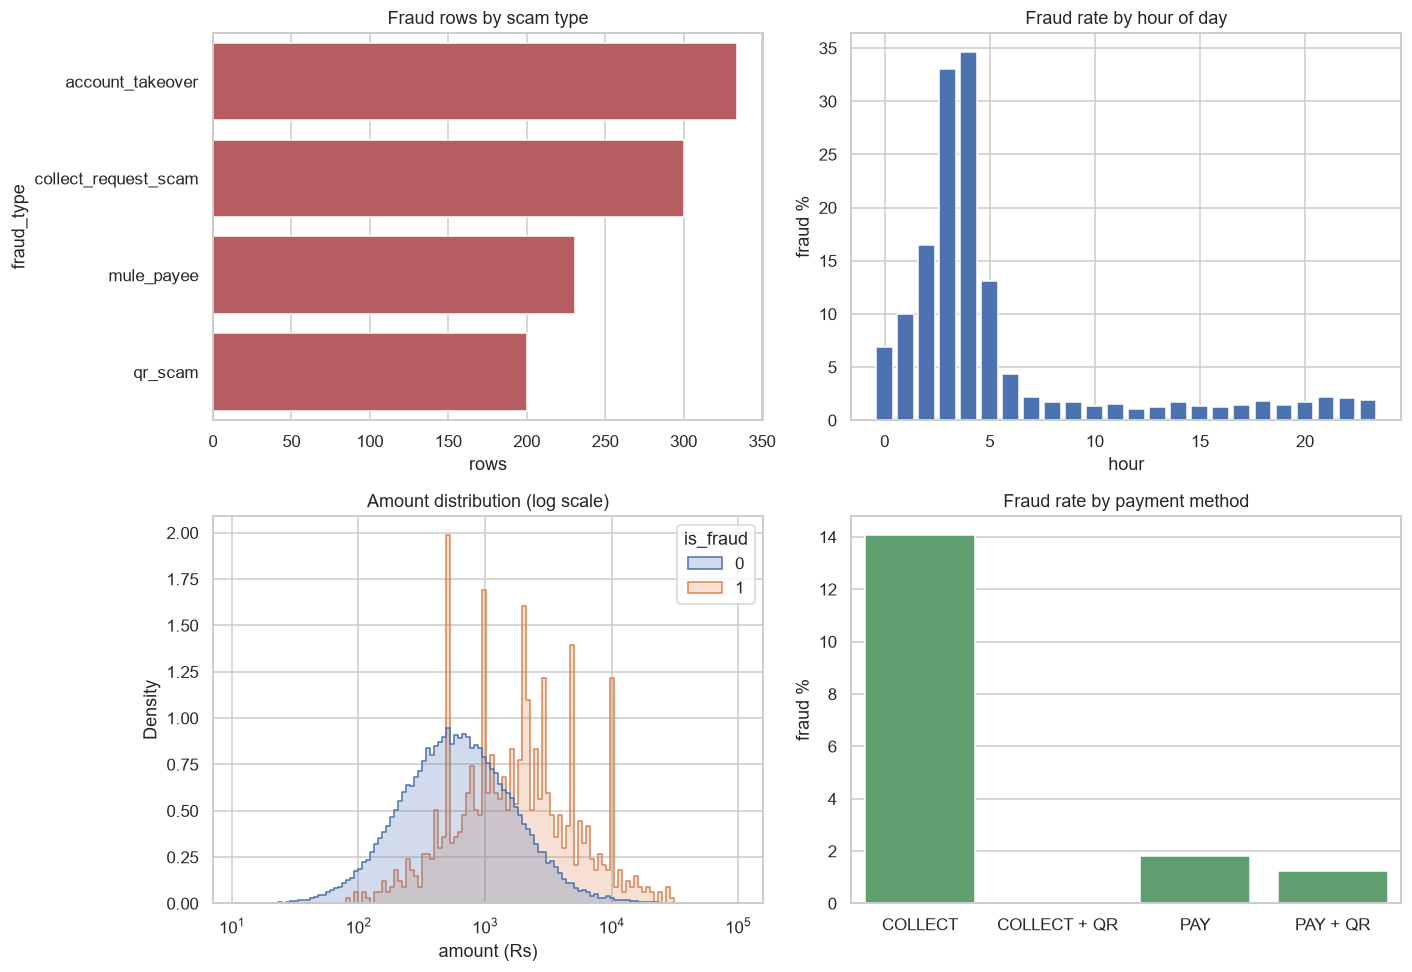

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

ft = df.loc[df.is_fraud == 1, "fraud_type"].value_counts()
sns.barplot(x=ft.values, y=ft.index, ax=axes[0, 0], color="#c44e52")
axes[0, 0].set_title("Fraud rows by scam type"); axes[0, 0].set_xlabel("rows")

hourly = df.assign(hour=df.timestamp.dt.hour).groupby("hour")["is_fraud"].mean() * 100
axes[0, 1].bar(hourly.index, hourly.values, color="#4c72b0")
axes[0, 1].set_title("Fraud rate by hour of day"); axes[0, 1].set_xlabel("hour"); axes[0, 1].set_ylabel("fraud %")

sns.histplot(data=df, x="amount", hue="is_fraud", log_scale=True, stat="density",
             common_norm=False, element="step", ax=axes[1, 0])
axes[1, 0].set_title("Amount distribution (log scale)"); axes[1, 0].set_xlabel("amount (Rs)")

req = df.groupby(["request_type", "via_qr"])["is_fraud"].mean().mul(100).reset_index()
req["method"] = req["request_type"] + np.where(req["via_qr"] == 1, " + QR", "")
sns.barplot(data=req, x="method", y="is_fraud", ax=axes[1, 1], color="#55a868")
axes[1, 1].set_title("Fraud rate by payment method"); axes[1, 1].set_ylabel("fraud %"); axes[1, 1].set_xlabel("")

plt.tight_layout(); plt.show()

**What the charts say**
- **Hour:** the fraud rate jumps between midnight and 6 AM (account takeovers happen while the victim sleeps).
- **Amount:** fraud amounts are spread higher, but they overlap heavily with normal amounts. *Amount alone is not enough.*
- **Method:** COLLECT requests carry a much higher fraud rate than normal PAY. This matches the "approve to receive money" scam.

Raw columns only tell part of the story. The next step builds features about **each user's own normal behaviour**.

## 5. Feature engineering: "Is this normal for THIS user?"

Every feature uses **only past data** (what the bank knows at payment time). This avoids **data leakage**: no peeking into the future.

| Feature | Meaning | Catches |
|---|---|---|
| `amount_to_user_avg` | this amount / user's average of past payments | takeover, scams |
| `is_new_payee` | first-ever payment from this user to this payee | all scams |
| `is_new_device` | phone never seen before for this user | takeover |
| `sender_txns_last_1h` | user's payments in the previous hour | takeover burst |
| `is_night` | payment between 12 AM and 6 AM | takeover |
| `is_collect`, `via_qr` | payment method | collect / QR scams |
| `payee_is_merchant` | payee is a verified merchant | scams use personal accounts |
| `payee_account_age_days` | how old the payee's account is | fresh scam accounts |
| `payee_new_senders_24h` | new senders this payee got in the last 24h | mule accounts |
| `log_amount` | log of amount (tames the long tail) | general |

In [6]:
def build_features(df):
    d = df.sort_values(["sender_id", "timestamp"]).reset_index(drop=True)
    g = d.groupby("sender_id")

    # amount vs. this user's past average (shift(1) = exclude the current payment)
    past_avg = g["amount"].transform(lambda s: s.shift(1).expanding().mean())
    d["amount_to_user_avg"] = (d["amount"] / past_avg).fillna(1.0)   # first payment: no history yet

    d["is_new_payee"] = (d.groupby(["sender_id", "payee_id"]).cumcount() == 0).astype(int)
    first_txn = g.cumcount() == 0
    d["is_new_device"] = ((d.groupby(["sender_id", "device_id"]).cumcount() == 0) & ~first_txn).astype(int)

    # payments by this user in the previous 1 hour (rolling window counts the current one, so -1)
    d["sender_txns_last_1h"] = (d.set_index("timestamp").groupby("sender_id")["amount"]
                                  .rolling("1h").count().values - 1)

    # new senders this payee received in the previous 24 hours (excluding the current payment)
    d = d.sort_values(["payee_id", "timestamp"]).reset_index(drop=True)
    d["payee_new_senders_24h"] = (d.set_index("timestamp").groupby("payee_id")["is_new_payee"]
                                    .rolling("24h").sum().values - d["is_new_payee"].values)

    d["is_night"] = (d["timestamp"].dt.hour < 6).astype(int)
    d["is_collect"] = (d["request_type"] == "COLLECT").astype(int)
    d["log_amount"] = np.log1p(d["amount"])
    return d.sort_values("timestamp").reset_index(drop=True)


FEATURES = ["log_amount", "amount_to_user_avg", "is_new_payee", "is_new_device",
            "sender_txns_last_1h", "is_night", "is_collect", "via_qr",
            "payee_is_merchant", "payee_account_age_days", "payee_new_senders_24h"]

data = build_features(df)
data.groupby("is_fraud")[FEATURES].mean().T.rename(columns={0: "legit (avg)", 1: "fraud (avg)"})

is_fraud,legit (avg),fraud (avg)
log_amount,6.413,7.433
amount_to_user_avg,1.073,3.218
is_new_payee,0.477,0.799
is_new_device,0.010,0.082
sender_txns_last_1h,0.013,0.320
is_night,0.030,0.228
is_collect,0.066,0.282
via_qr,0.443,0.249
payee_is_merchant,0.553,0.000
payee_account_age_days,"1,527.367",235.144


The averages already separate the classes: fraud payments go far more often to **new payees**, from **new devices**, at **night**, to **young, non-merchant** accounts, and at **several times the user's usual amount**.

## 6. Time-based split

A random split would let the model train on *future* payments and test on the past. That leaks information and inflates scores. A real bank trains on history and scores tomorrow's payments, so I split by month:

- **Train:** January to April
- **Validation:** May (used only to choose the alert threshold)
- **Test:** June (touched once, for the final honest score)

In [7]:
month = data["timestamp"].dt.month
train, val, test = data[month <= 4], data[month == 5], data[month == 6]
X_train, y_train = train[FEATURES], train["is_fraud"]
X_val, y_val = val[FEATURES], val["is_fraud"]
X_test, y_test = test[FEATURES], test["is_fraud"]

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:>10}: {len(part):6,} rows | fraud {part.is_fraud.sum():4} ({part.is_fraud.mean():.2%})")

     train: 35,470 rows | fraud  756 (2.13%)
validation:  9,059 rows | fraud  166 (1.83%)
      test:  8,367 rows | fraud  143 (1.71%)


## 7. Models

Three models, from simple to strong:
1. **Logistic Regression**: the baseline, fully interpretable.
2. **Random Forest**: many decision trees voting together.
3. **XGBoost**: trees built one after another, each fixing the previous one's mistakes. Usually the best on tabular data.

**Class imbalance:** I use class weights (`class_weight` / `scale_pos_weight`) so that a missed fraud costs the model more during training.
*Why not SMOTE?* SMOTE invents fake fraud rows by blending real ones. Class weights reach the same goal without creating artificial data, and they are simpler to explain.

In [8]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
                             colsample_bytree=0.9, scale_pos_weight=pos_weight,
                             eval_metric="aucpr", random_state=SEED),
}

results, test_scores = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p_val, p_test = model.predict_proba(X_val)[:, 1], model.predict_proba(X_test)[:, 1]
    test_scores[name] = p_test
    results.append({"model": name,
                    "val PR-AUC": average_precision_score(y_val, p_val),
                    "test PR-AUC": average_precision_score(y_test, p_test),
                    "test ROC-AUC": roc_auc_score(y_test, p_test)})

pd.DataFrame(results).set_index("model")

,val PR-AUC,test PR-AUC,test ROC-AUC
model,,,
Logistic Regression,0.823,0.848,0.997
Random Forest,0.945,0.943,0.999
XGBoost,0.946,0.953,0.999


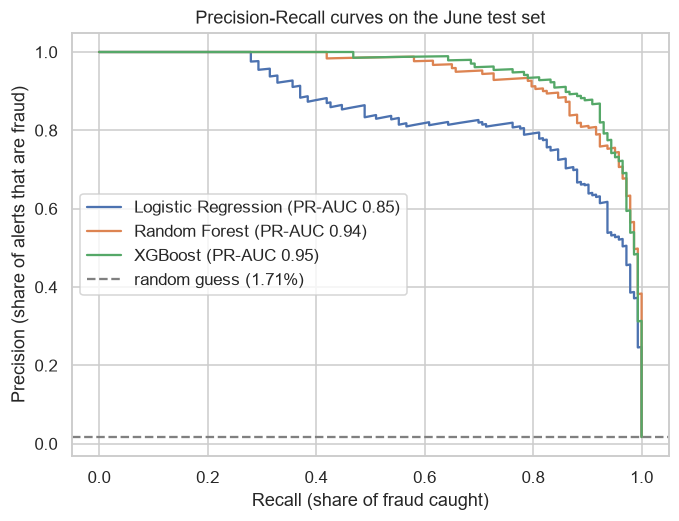

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in test_scores.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.2f})")
ax.axhline(y_test.mean(), ls="--", c="grey", label=f"random guess ({y_test.mean():.2%})")
ax.set_xlabel("Recall (share of fraud caught)"); ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Precision-Recall curves on the June test set"); ax.legend(); plt.show()

**Reading the result:** the further a curve sits to the top-right, the better. The tree models beat the linear baseline because fraud depends on *combinations* of signals (for example, a new device **and** night time **and** a high amount), which trees capture naturally. I keep **XGBoost** as the final model.

Two honest notes for the interview:
- **ROC-AUC looks near-perfect for every model, so it is not useful here.** With 98% legit payments, ROC-AUC stays high even when many alerts are wrong. PR-AUC separates the models much better.
- **These scores are high because synthetic patterns are cleaner than real life.** On real bank data I would expect a clearly lower PR-AUC. The *method* (features, time split, cost threshold, explanations) is what carries over.

## 8. Score payments with the final model

The XGBoost model gives every validation and test payment a **risk score** between 0 and 1. The next section turns these scores into decisions.

Later I also check recall **per scam type**. An overall score can hide weak spots, and because I know each fraud row's scam type, I can see exactly which scams slip through. A random Kaggle CSV cannot give you this.

In [10]:
model = models["XGBoost"]
val_p = model.predict_proba(X_val)[:, 1]
test = test.assign(score=model.predict_proba(X_test)[:, 1])

## 9. Cost-based threshold and risk tiers

A model outputs a **risk score** from 0 to 1. Where do we draw the line? Business cost decides, not 0.5:

- **Missed fraud** (false negative) → the customer loses the **full amount**.
- **False alarm** (false positive) → an extra OTP step or a support call, roughly **₹50 of friction**.

I try every threshold on the **validation** month and pick the one with the lowest total cost.

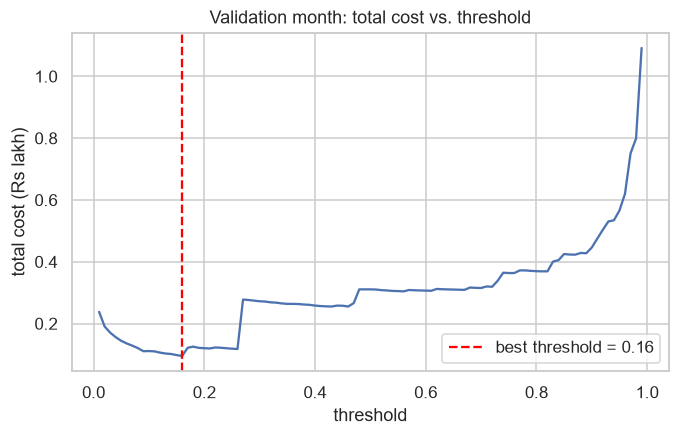

In [11]:
FALSE_ALARM_COST = 50  # Rs of customer friction per unnecessary alert

def total_cost(y, score, amount, t):
    flagged = score >= t
    missed_loss = amount[(y == 1) & ~flagged].sum()
    false_alarms = ((y == 0) & flagged).sum()
    return missed_loss + FALSE_ALARM_COST * false_alarms

thresholds = np.linspace(0.01, 0.99, 99)
costs = [total_cost(y_val.values, val_p, val["amount"].values, t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, np.array(costs) / 1e5)
ax.axvline(best_t, c="red", ls="--", label=f"best threshold = {best_t:.2f}")
ax.set_xlabel("threshold"); ax.set_ylabel("total cost (Rs lakh)")
ax.set_title("Validation month: total cost vs. threshold"); ax.legend(); plt.show()

**Risk tiers.** Real UPI apps do not just say yes or no. Instead of blocking every alert, I use three tiers:
- **Block**: score so high that, on validation, at least 90% of such payments were fraud.
- **OTP step-up**: suspicious but not certain. Ask for extra verification; a genuine user passes in seconds.
- **Allow**: everything below the cost-optimal threshold.

In [12]:
prec, rec, thr = precision_recall_curve(y_val, val_p)
ok = (prec[:-1] >= 0.90) & (thr >= best_t)
block_t = float(thr[ok].min()) if ok.any() else 0.99
print(f"OTP step-up threshold: {best_t:.2f} | Block threshold: {block_t:.2f}")

def decide(score):
    return np.where(score >= block_t, "Block", np.where(score >= best_t, "OTP step-up", "Allow"))

test["decision"] = decide(test["score"].values)
pd.crosstab(test["decision"], test["is_fraud"].map({0: "legit", 1: "fraud"}), margins=True)

OTP step-up threshold: 0.16 | Block threshold: 0.92


is_fraud,fraud,legit,All
decision,,,
Allow,2,8094,8096
Block,119,10,129
OTP step-up,22,120,142
All,143,8224,8367


In [13]:
flag = test["score"] >= best_t
y, amt = test["is_fraud"], test["amount"]
fraud_amt = amt[y == 1].sum()
caught_amt = amt[(y == 1) & flag].sum()
false_alarms = int(((y == 0) & flag).sum())
net_saved = caught_amt - FALSE_ALARM_COST * false_alarms

print("JUNE TEST MONTH: BUSINESS IMPACT")
print(f"  Fraud attempted : Rs {fraud_amt:12,.0f}  ({int(y.sum())} payments)")
print(f"  Fraud stopped   : Rs {caught_amt:12,.0f}  ({caught_amt / fraud_amt:.1%} of fraud value)")
print(f"  False alarms    : {false_alarms} legit payments got an extra OTP "
      f"({false_alarms / (y == 0).sum():.2%} of legit traffic)")
print(f"  Net saved       : Rs {net_saved:12,.0f}  after Rs {FALSE_ALARM_COST}/false-alarm friction")
print(f"\n  Recall {((y == 1) & flag).sum() / y.sum():.1%} | Precision {((y == 1) & flag).sum() / flag.sum():.1%}")

JUNE TEST MONTH: BUSINESS IMPACT
  Fraud attempted : Rs      358,328  (143 payments)
  Fraud stopped   : Rs      358,085  (99.9% of fraud value)
  False alarms    : 130 legit payments got an extra OTP (1.58% of legit traffic)
  Net saved       : Rs      351,585  after Rs 50/false-alarm friction

  Recall 98.6% | Precision 52.0%


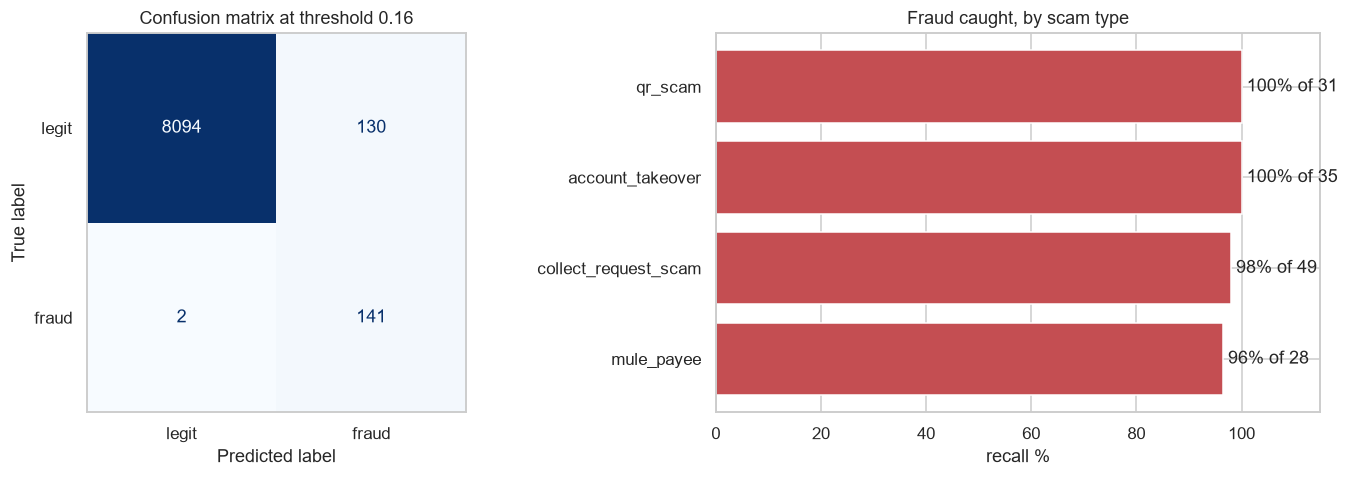

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, flag), display_labels=["legit", "fraud"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix at threshold {best_t:.2f}"); axes[0].grid(False)

by_type = (test[test.is_fraud == 1].assign(caught=flag[test.is_fraud == 1])
           .groupby("fraud_type")["caught"].agg(["mean", "size"]).sort_values("mean"))
axes[1].barh(by_type.index, by_type["mean"] * 100, color="#c44e52")
for i, (r, n) in enumerate(zip(by_type["mean"], by_type["size"])):
    axes[1].text(r * 100 + 1, i, f"{r:.0%} of {n}", va="center")
axes[1].set_xlim(0, 115); axes[1].set_xlabel("recall %"); axes[1].set_title("Fraud caught, by scam type")
plt.tight_layout(); plt.show()

**Takeaway:** per-type recall shows *where* the model is strong and where it is weak. Scam types whose payments look like normal behaviour (familiar amount, usual phone, daytime) are naturally the hardest. Better signals for them, such as payee reports, would come from outside the transaction itself.

## 10. Explainability: why was this payment flagged?

A fraud team, a regulator, or an angry customer will ask **"why?"**. I use **SHAP**:
- For every payment, SHAP splits the risk score into a contribution from each feature.
- Positive contribution = pushed towards fraud; negative = pushed towards legit.
- Contributions add up to the final score. That makes SHAP fair and consistent.

### 10a. Global view: what drives the model overall?

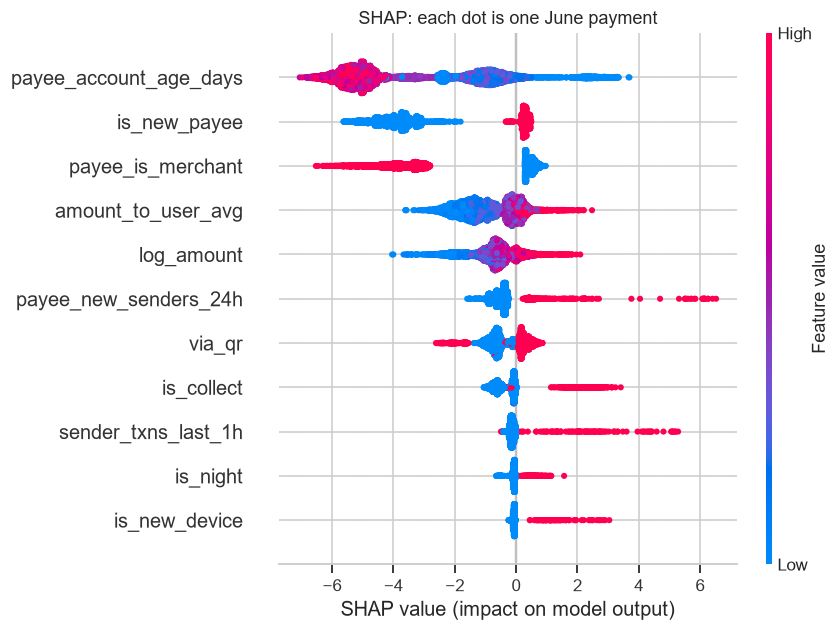

In [15]:
explainer = shap.TreeExplainer(model)
sv = explainer(X_test)
shap.plots.beeswarm(sv, max_display=11, show=False)
plt.title("SHAP: each dot is one June payment"); plt.tight_layout(); plt.show()

**How to read it:** features are ranked by impact. Red = high feature value, blue = low. Dots to the right push towards fraud (the x-axis is in the model's internal log-odds units, so only direction and size matter). For example, red dots on the right for `is_new_device` mean "a new device pushes the risk up". Blue dots on the right for `payee_account_age_days` mean "a *young* payee account pushes the risk up".

### 10b. Local view: plain-English reason codes for each decision

In [16]:
def reason_text(feat, v):
    texts = {
        "amount_to_user_avg": f"amount is {v:.1f}x this user's usual",
        "is_new_payee": "first-ever payment to this payee" if v else "regular payee",
        "is_new_device": "payment from a new / unknown device" if v else "usual device",
        "sender_txns_last_1h": f"{int(v)} other payments in the last hour",
        "is_night": "made between 12 AM and 6 AM" if v else "daytime payment",
        "is_collect": "user approved a money REQUEST (collect)" if v else "normal PAY",
        "via_qr": "paid by scanning a QR code" if v else "not a QR payment",
        "payee_is_merchant": "payee is a verified merchant" if v else "payee is an individual, not a merchant",
        "payee_account_age_days": f"payee account is {int(v)} days old",
        "payee_new_senders_24h": f"payee received money from {int(v)} new senders in 24h",
        "log_amount": f"amount Rs {np.expm1(v):,.0f}",
    }
    return texts[feat]

test_pos = {idx: i for i, idx in enumerate(test.index)}

def explain(idx, top=3):
    row, i = test.loc[idx], test_pos[idx]
    contrib = pd.Series(sv.values[i], index=FEATURES).sort_values(ascending=False)
    reasons = [reason_text(f, row[f]) for f, c in contrib.items() if c > 0][:top]
    print(f"{row.txn_id} | Rs {row.amount:,.0f} | {row.request_type}{' via QR' if row.via_qr else ''} "
          f"| {row.timestamp:%d-%b %H:%M}")
    print(f"  Truth: {row.fraud_type:<22} Risk score: {row.score:.2f}  ->  DECISION: {row.decision}")
    for r in reasons:
        print(f"   - {r}")
    print()

# one caught example per scam type, plus one false alarm and one miss (honesty!)
caught = test[(test.is_fraud == 1) & (test.score >= best_t)]
for ftype in caught["fraud_type"].unique():
    explain(caught[caught.fraud_type == ftype]["score"].idxmax())

false_alarm = test[(test.is_fraud == 0) & (test.score >= best_t)]
if len(false_alarm):
    print("---- A FALSE ALARM (legit payment that got flagged) ----")
    explain(false_alarm["score"].idxmax())

missed = test[(test.is_fraud == 1) & (test.score < best_t)]
if len(missed):
    print("---- A MISSED FRAUD ----")
    explain(missed["score"].idxmin())

T047707 | Rs 9,999 | PAY via QR | 12-Jun 10:36
  Truth: qr_scam                Risk score: 1.00  ->  DECISION: Block
   - payee account is 46 days old
   - amount is 12.7x this user's usual
   - amount Rs 9,999

T049274 | Rs 9,999 | COLLECT | 17-Jun 15:46
  Truth: collect_request_scam   Risk score: 1.00  ->  DECISION: Block
   - payee account is 49 days old
   - user approved a money REQUEST (collect)
   - amount is 22.7x this user's usual

T048854 | Rs 5,444 | PAY | 16-Jun 03:41
  Truth: account_takeover       Risk score: 1.00  ->  DECISION: Block
   - 2 other payments in the last hour
   - payee account is 58 days old
   - payee received money from 1 new senders in 24h

T047079 | Rs 499 | PAY via QR | 10-Jun 04:26
  Truth: mule_payee             Risk score: 1.00  ->  DECISION: Block
   - payee received money from 9 new senders in 24h
   - payee account is 32 days old
   - amount Rs 499

---- A FALSE ALARM (legit payment that got flagged) ----
T052725 | Rs 1,728 | COLLECT | 29-Jun 13:

For a single payment, a **waterfall plot** shows exactly how each feature moves the score from the average to the final value:

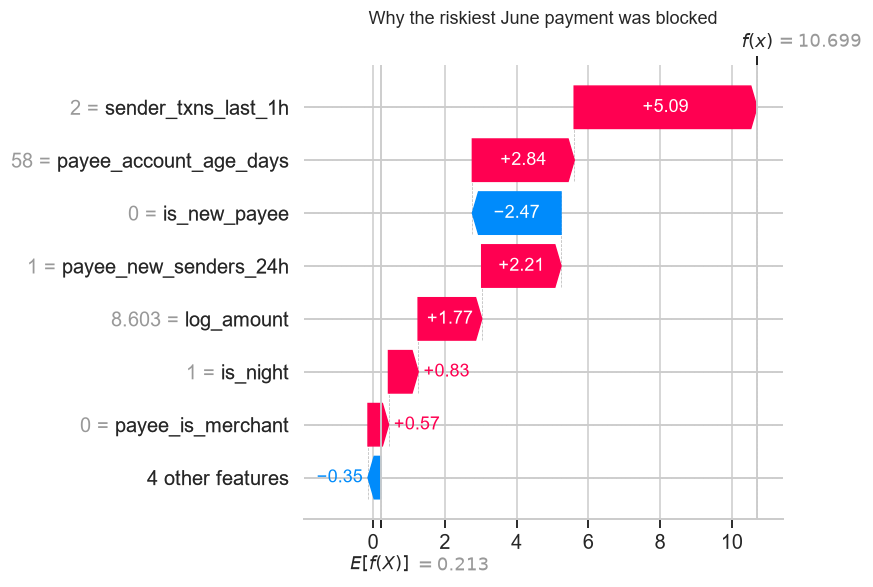

In [17]:
i = test_pos[caught["score"].idxmax()]
shap.plots.waterfall(sv[i], max_display=8, show=False)
plt.title("Why the riskiest June payment was blocked"); plt.tight_layout(); plt.show()

## 11. Conclusion

**What I built**
- A **realistic synthetic UPI dataset** with 4 named scam patterns and natural noise.
- **Behaviour features** computed only from the past (no leakage).
- A **time-based** evaluation that mimics deployment.
- An **XGBoost** model compared against Logistic Regression and Random Forest using **PR-AUC**.
- A **cost-based threshold** that maximises rupees saved, plus **Allow / OTP / Block** tiers.
- **SHAP reason codes** that explain every decision in plain English, including the mistakes.

**Limitations (stated honestly)**
- The data is synthetic. Real fraud is noisier and changes as scammers adapt (*concept drift*).
- The ₹50 false-alarm cost is an assumption; a bank would measure it.
- I assume an OTP stops the fraud. Social-engineering victims sometimes share the OTP.
- No network view: real mule rings link many accounts together.

**Next steps**
1. Wrap the model in a small **API** (FastAPI) that scores a payment in milliseconds.
2. Add **graph features** (shared devices or payees across accounts) to catch mule rings.
3. **Monitor drift** monthly and retrain when fraud patterns shift.
4. Feed **customer fraud reports** back in as fresh labels.